In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/README.dataset.txt
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/README.roboflow.txt
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/001_jpg.rf.4e68c60b740dfb573ae743bc71df83e2.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/003_jpg.rf.4bbaea88cef2fe3ec5e2f7d0af935f6a.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/004_jpg.rf.403e439be69fbeb646bf7010aaf52ed0.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/005_jpg.rf.f2248d837b7b97b5870fc8796a0eefd8.jpg
/kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format/test/006_jpg.rf.

In [2]:
%pip install -q "ultralytics>=8.3,<9" pyyaml

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Imports

import json
import math
import shutil
import platform
import random

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import yaml
import torch
import ultralytics
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Polygon
from ultralytics import YOLO


# Experiment Configuration

SEED = 42
EPOCHS = 60
IMAGE_SIZE = 640
BATCH_SIZE = 8

COCO_ROOT = Path(
    "/kaggle/input/datasets/wayanradityaputra/"
    "panoptic-indoor-segmentation-v5-coco-format"
)

WORK_ROOT = Path("/kaggle/working")

OUTPUT_ROOT = WORK_ROOT / "panoptic_from_coco_yolo"
DATA_YAML = OUTPUT_ROOT / "data.yaml"

EXPERIMENT_ROOT = WORK_ROOT / "experiments"
RUN_NAME = "baseline_yolo11n_all74_coco"

EXPECTED = {
    "train": {"images": 397, "annotations": 4479},
    "valid": {"images": 166, "annotations": 2022},
    "test": {"images": 359, "annotations": 5344},
}

SPLITS = ["train", "valid", "test"]


# Reproducibility

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# Environment Check

assert COCO_ROOT.is_dir(), "COCO dataset belum terpasang!"
assert torch.cuda.is_available(), "GPU Kaggle belum aktif!"

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("COCO dataset:", COCO_ROOT)

print("\nENVIRONMENT READY")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.216
GPU: Tesla T4
COCO dataset: /kaggle/input/datasets/wayanradityaputra/panoptic-indoor-segmentation-v5-coco-format

ENVIRONMENT READY


In [4]:
# Source Dataset Verification

coco_by_split = {}
reference_names = None

for split in SPLITS:

    annotation_path = (
        COCO_ROOT / split / "_annotations.coco.json"
    )

    assert annotation_path.is_file(), (
        f"Annotation JSON missing: {annotation_path}"
    )

    with open(annotation_path, "r") as f:
        coco = json.load(f)

    images = coco["images"]
    annotations = coco["annotations"]
    categories = coco["categories"]

    assert len(images) == EXPECTED[split]["images"]
    assert len(annotations) == EXPECTED[split]["annotations"]
    assert len(categories) == 75

    category_map = {
        category["id"]: category["name"]
        for category in categories
    }

    assert set(category_map) == set(range(75))
    assert category_map[0] == "indoor-objects"

    names = [category_map[i] for i in range(1, 75)]

    if reference_names is None:
        reference_names = names
    else:
        assert names == reference_names

    image_ids = [image["id"] for image in images]

    assert len(image_ids) == len(set(image_ids))

    image_id_set = set(image_ids)

    for annotation in annotations:
        assert annotation["image_id"] in image_id_set
        assert 1 <= annotation["category_id"] <= 74

    coco_by_split[split] = coco

    present_classes = len(
        set(a["category_id"] for a in annotations)
    )

    print(
        f"{split.upper():5} | "
        f"Images: {len(images):3} | "
        f"Instances: {len(annotations):5} | "
        f"Classes: {present_classes}"
    )


# Dataset Summary

CLASS_NAMES = reference_names
NC = len(CLASS_NAMES)

assert NC == 74

total_images = sum(
    len(coco_by_split[s]["images"])
    for s in SPLITS
)

total_instances = sum(
    len(coco_by_split[s]["annotations"])
    for s in SPLITS
)

assert total_images == 922
assert total_instances == 11845

print("\nTotal images:", total_images)
print("Total instances:", total_instances)
print("Trainable classes:", NC)
print("Unused COCO category 0: confirmed")

print("\nSOURCE DATASET VERIFIED")

TRAIN | Images: 397 | Instances:  4479 | Classes: 65
VALID | Images: 166 | Instances:  2022 | Classes: 58
TEST  | Images: 359 | Instances:  5344 | Classes: 69

Total images: 922
Total instances: 11845
Trainable classes: 74
Unused COCO category 0: confirmed

SOURCE DATASET VERIFIED


In [5]:
# COCO to YOLO Segmentation Conversion

rotation_fixes = {
    (
        "train",
        "182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30dfed.jpg"
    ): "CCW",

    (
        "train",
        "182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4a15.jpg"
    ): "CCW",

    (
        "valid",
        "182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381fe7.jpg"
    ): "CW",

    (
        "valid",
        "182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8790.jpg"
    ): "CCW",
}


# Coordinate Transformation

def transform_polygon(xy, coco_width, coco_height, rotation):
    if rotation is None:
        return xy.copy()

    x = xy[:, 0]
    y = xy[:, 1]

    if rotation == "CW":
        return np.column_stack([
            coco_height - y,
            x
        ])

    if rotation == "CCW":
        return np.column_stack([
            y,
            coco_width - x
        ])

    raise ValueError(f"Unknown rotation: {rotation}")


# Prepare Output

if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)

converted_total = 0
converted_images = 0
applied_fixes = []


# Convert Each Split

for split in SPLITS:
    coco = coco_by_split[split]

    source_dir = COCO_ROOT / split
    images_dir = OUTPUT_ROOT / split / "images"
    labels_dir = OUTPUT_ROOT / split / "labels"

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    image_map = {
        image["id"]: image
        for image in coco["images"]
    }

    image_dimensions = {}
    annotations_by_image = defaultdict(list)
    used_stems = set()


    # Validate Actual Image Dimensions

    for image in coco["images"]:
        source_image = source_dir / image["file_name"]

        assert source_image.is_file(), (
            f"Missing image: {source_image}"
        )

        stem = source_image.stem
        assert stem not in used_stems
        used_stems.add(stem)

        with Image.open(source_image) as img:
            actual_width, actual_height = img.size

        coco_width = int(image["width"])
        coco_height = int(image["height"])

        key = (split, image["file_name"])
        rotation = rotation_fixes.get(key)

        if (actual_width, actual_height) != (
            coco_width, coco_height
        ):
            assert rotation in ("CW", "CCW"), (
                f"Unexpected dimension mismatch: {key}"
            )

            assert (actual_width, actual_height) == (
                coco_height, coco_width
            ), f"Unexpected dimensions: {key}"

            applied_fixes.append({
                "split": split,
                "file_name": image["file_name"],
                "rotation": rotation,
                "coco_dimensions": [coco_width, coco_height],
                "actual_dimensions": [actual_width, actual_height]
            })

        else:
            assert rotation is None, (
                f"Rotation specified without mismatch: {key}"
            )

        image_dimensions[image["id"]] = (
            actual_width,
            actual_height
        )

        shutil.copy2(
            source_image,
            images_dir / source_image.name
        )


    # Convert Instance Annotations

    for ann in coco["annotations"]:
        image = image_map[ann["image_id"]]

        coco_width = int(image["width"])
        coco_height = int(image["height"])

        actual_width, actual_height = image_dimensions[
            ann["image_id"]
        ]

        segmentation = ann["segmentation"]

        if (
            isinstance(segmentation, list)
            and len(segmentation) == 1
            and isinstance(segmentation[0], list)
        ):
            polygon = segmentation[0]

        elif (
            isinstance(segmentation, list)
            and len(segmentation) >= 6
            and isinstance(segmentation[0], (int, float))
        ):
            polygon = segmentation

        else:
            raise ValueError(
                f"Invalid segmentation: {ann['id']}"
            )

        assert len(polygon) >= 6
        assert len(polygon) % 2 == 0

        xy = np.asarray(
            polygon,
            dtype=np.float64
        ).reshape(-1, 2)

        assert np.isfinite(xy).all()

        key = (split, image["file_name"])
        rotation = rotation_fixes.get(key)

        transformed = transform_polygon(
            xy,
            coco_width,
            coco_height,
            rotation
        )

        normalized = transformed / np.array(
            [actual_width, actual_height],
            dtype=np.float64
        )

        if (
            not np.isfinite(normalized).all()
            or (normalized < 0).any()
            or (normalized > 1).any()
        ):
            raise ValueError(
                f"Invalid transformed coordinates: "
                f"{split}, annotation={ann['id']}"
            )

        class_id = int(ann["category_id"]) - 1

        assert 0 <= class_id < NC

        coordinates = " ".join(
            f"{value:.10f}"
            for value in normalized.flatten()
        )

        annotations_by_image[ann["image_id"]].append(
            f"{class_id} {coordinates}"
        )


    # Save YOLO Labels

    for image in coco["images"]:
        stem = Path(image["file_name"]).stem
        label_path = labels_dir / f"{stem}.txt"

        lines = annotations_by_image[image["id"]]

        label_path.write_text(
            "\n".join(lines) + ("\n" if lines else ""),
            encoding="utf-8"
        )

    instance_count = sum(
        len(lines)
        for lines in annotations_by_image.values()
    )

    assert instance_count == EXPECTED[split]["annotations"]

    converted_total += instance_count
    converted_images += len(coco["images"])

    print(
        f"{split.upper():5} | "
        f"Images: {len(coco['images'])} | "
        f"Instances: {instance_count}"
    )


# Verify All Rotation Fixes

expected_keys = set(rotation_fixes)

actual_keys = {
    (item["split"], item["file_name"])
    for item in applied_fixes
}

assert actual_keys == expected_keys, (
    "Not all expected orientation fixes were applied"
)

assert converted_images == 922
assert converted_total == 11845


# Create Dataset YAML

dataset_config = {
    "path": str(OUTPUT_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": NC,
    "names": CLASS_NAMES
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(
        dataset_config,
        f,
        sort_keys=False,
        allow_unicode=True
    )


# Save Conversion Metadata

conversion_manifest = {
    "source": str(COCO_ROOT),
    "destination": str(OUTPUT_ROOT),
    "source_format": "COCO Segmentation",
    "target_format": "YOLO Instance Segmentation",
    "class_mapping": "yolo_id = coco_category_id - 1",
    "excluded_category": {
        "id": 0,
        "name": "indoor-objects",
        "annotation_count": 0
    },
    "number_of_classes": NC,
    "total_images": converted_images,
    "total_instances": converted_total,
    "coordinate_clipping": False,
    "orientation_fixes": applied_fixes,
    "splits": EXPECTED
}

with open(
    OUTPUT_ROOT / "conversion_manifest.json", "w"
) as f:
    json.dump(conversion_manifest, f, indent=2)


# Conversion Summary

print("\nCONVERSION COMPLETE")
print("Images:", converted_images)
print("Instances:", converted_total)
print("Classes:", NC)
print("Orientation fixes:", len(applied_fixes))
print("Dataset:", OUTPUT_ROOT)

TRAIN | Images: 397 | Instances: 4479
VALID | Images: 166 | Instances: 2022
TEST  | Images: 359 | Instances: 5344

CONVERSION COMPLETE
Images: 922
Instances: 11845
Classes: 74
Orientation fixes: 4
Dataset: /kaggle/working/panoptic_from_coco_yolo


In [6]:
# Converted Dataset Validation

with open(DATA_YAML) as f:
    config = yaml.safe_load(f)

assert config["nc"] == 74
assert config["names"] == CLASS_NAMES

all_class_counts = {}
total_instances_checked = 0

for split in SPLITS:

    images_dir = OUTPUT_ROOT / split / "images"
    labels_dir = OUTPUT_ROOT / split / "labels"

    image_files = [
        p for p in images_dir.iterdir()
        if p.is_file()
    ]

    label_files = list(labels_dir.glob("*.txt"))

    assert len(image_files) == EXPECTED[split]["images"]
    assert len(label_files) == EXPECTED[split]["images"]

    assert (
        {p.stem for p in image_files}
        == {p.stem for p in label_files}
    )

    class_counts = Counter()
    instance_count = 0

    for label_file in label_files:

        lines = label_file.read_text().splitlines()

        for line_number, line in enumerate(lines, 1):

            parts = line.split()

            assert len(parts) >= 7, (
                f"Too few values: {label_file.name}"
            )

            class_id = int(parts[0])

            coordinates = np.array(
                [float(v) for v in parts[1:]],
                dtype=np.float64
            )

            assert 0 <= class_id < NC

            assert len(coordinates) >= 6
            assert len(coordinates) % 2 == 0

            assert np.isfinite(coordinates).all()

            assert (
                (coordinates >= 0).all()
                and (coordinates <= 1).all()
            ), (
                f"Out-of-bounds: "
                f"{label_file.name}:{line_number}"
            )

            class_counts[class_id] += 1
            instance_count += 1

    assert instance_count == EXPECTED[split]["annotations"]

    all_class_counts[split] = class_counts
    total_instances_checked += instance_count

    print(
        f"{split.upper():5} | "
        f"Images: {len(image_files):3} | "
        f"Instances: {instance_count:5} | "
        f"Present classes: {len(class_counts)}"
    )

assert total_instances_checked == 11845


# Identify Classes Missing from Training

missing_train_classes = [
    {
        "class_id": i,
        "class_name": CLASS_NAMES[i]
    }
    for i in range(NC)
    if all_class_counts["train"][i] == 0
]


# Save Dataset Quality Report

qa_report = {
    "total_instances_validated": total_instances_checked,
    "out_of_bounds": 0,
    "class_id_errors": 0,
    "missing_train_classes": missing_train_classes,
    "class_counts": {
        split: {
            str(k): v
            for k, v in counts.items()
        }
        for split, counts in all_class_counts.items()
    }
}

with open(OUTPUT_ROOT / "qa_report.json", "w") as f:
    json.dump(qa_report, f, indent=2)

print("\nClasses absent from training:")

for item in missing_train_classes:
    print(item["class_id"], item["class_name"])

print("\nTOTAL VALIDATED:", total_instances_checked)
print("DATASET VALIDATION PASSED")

TRAIN | Images: 397 | Instances:  4479 | Present classes: 65
VALID | Images: 166 | Instances:  2022 | Present classes: 58
TEST  | Images: 359 | Instances:  5344 | Present classes: 69

Classes absent from training:
22 flower
25 hair drier
27 keyboard
33 mouse
46 scissor
47 scissors
55 teddy bear
56 toaster
58 toothbrush

TOTAL VALIDATED: 11845
DATASET VALIDATION PASSED


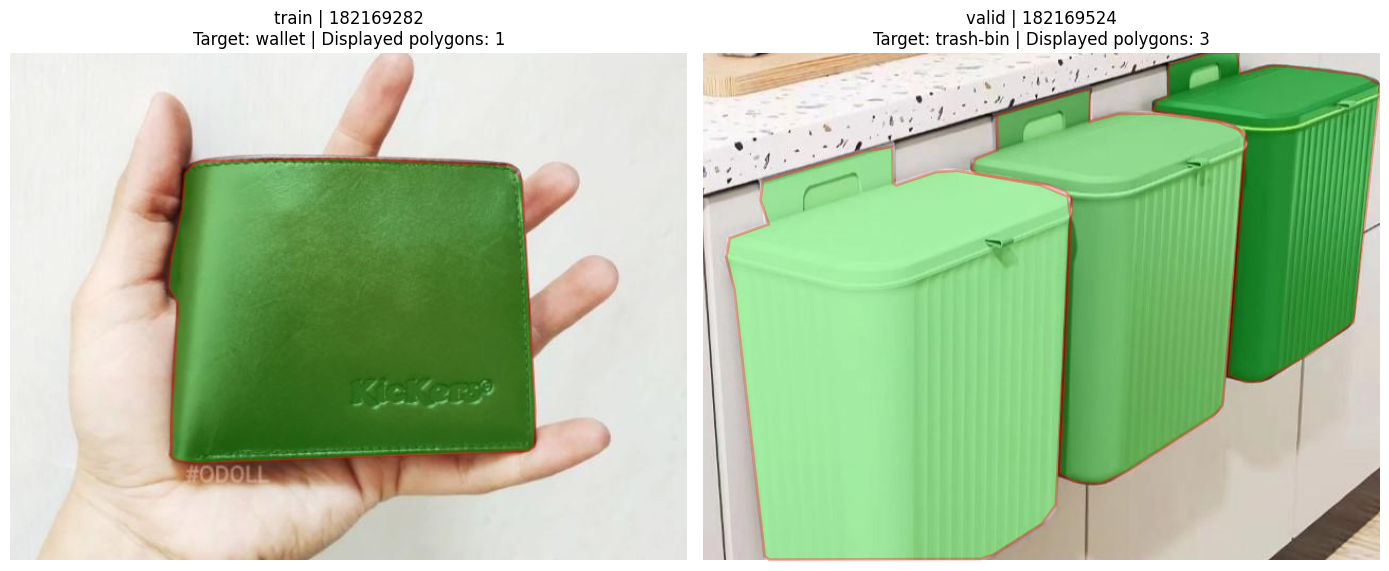

Visualization saved: /kaggle/working/rebuilt_yolo_mask_inspection.png


In [7]:
# Visual Inspection

samples = [
    ("train", "182169282", "wallet"),
    ("valid", "182169524", "trash-bin"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (split, prefix, target_class) in zip(
    axes, samples
):

    images_dir = OUTPUT_ROOT / split / "images"
    labels_dir = OUTPUT_ROOT / split / "labels"

    candidates = [
        p for p in images_dir.iterdir()
        if p.name.startswith(prefix)
    ]

    if not candidates:
        print(f"Image not found: {split}/{prefix}")
        ax.set_title(f"Not found: {prefix}")
        ax.axis("off")
        continue

    image_path = candidates[0]

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    label_path = (
        labels_dir / f"{image_path.stem}.txt"
    )

    lines = label_path.read_text().splitlines()

    target_id = CLASS_NAMES.index(target_class)

    selected = [
        line for line in lines
        if int(line.split()[0]) == target_id
    ]

    if not selected:
        print(
            f"{target_class} not found in {image_path.name}; "
            "showing first 3 annotations instead."
        )
        selected = lines[:3]

    ax.imshow(image)

    for line in selected:

        parts = line.split()
        class_id = int(parts[0])

        xy = np.array(
            [float(v) for v in parts[1:]]
        ).reshape(-1, 2)

        xy[:, 0] *= width
        xy[:, 1] *= height

        polygon = Polygon(
            xy,
            closed=True,
            facecolor="lime",
            edgecolor="red",
            linewidth=2,
            alpha=0.3
        )

        ax.add_patch(polygon)

    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)

    ax.set_title(
        f"{split} | {prefix}\n"
        f"Target: {target_class} | "
        f"Displayed polygons: {len(selected)}"
    )

    ax.axis("off")

plt.tight_layout()


# Save Visualization

figure_path = (
    WORK_ROOT / "rebuilt_yolo_mask_inspection.png"
)

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved:", figure_path)

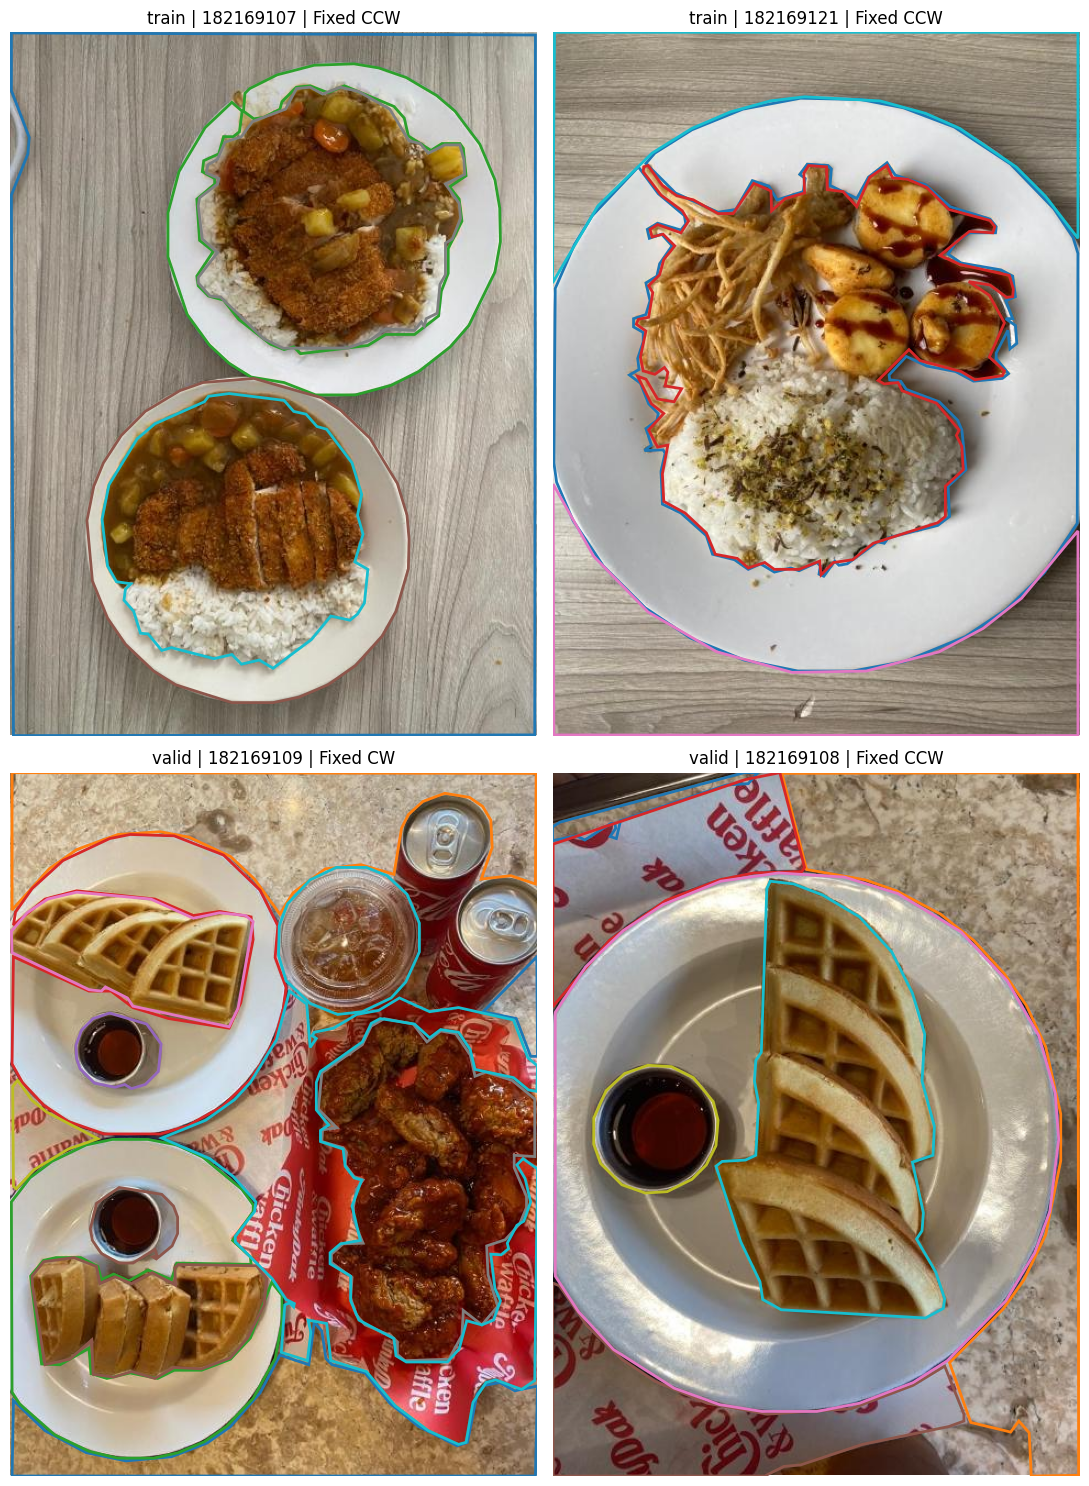

Saved: /kaggle/working/orientation_fixes_verification.png


In [8]:
# Verify Repaired YOLO Masks

fig, axes = plt.subplots(2, 2, figsize=(11, 15))

for ax, ((split, filename), rotation) in zip(
    axes.flat,
    rotation_fixes.items()
):
    image_path = OUTPUT_ROOT / split / "images" / filename
    label_path = (
        OUTPUT_ROOT / split / "labels"
        / f"{Path(filename).stem}.txt"
    )

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image)

    lines = label_path.read_text().splitlines()
    colors = plt.cm.tab10(np.linspace(0, 1, len(lines)))

    for index, line in enumerate(lines):
        parts = line.split()

        xy = np.asarray(
            [float(v) for v in parts[1:]],
            dtype=np.float64
        ).reshape(-1, 2)

        xy[:, 0] *= width
        xy[:, 1] *= height

        patch = Polygon(
            xy,
            closed=True,
            fill=False,
            edgecolor=colors[index],
            linewidth=2
        )

        ax.add_patch(patch)

    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.set_title(
        f"{split} | {filename[:9]} | Fixed {rotation}"
    )
    ax.axis("off")

plt.tight_layout()

repair_preview_path = (
    WORK_ROOT / "orientation_fixes_verification.png"
)

plt.savefig(
    repair_preview_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved:", repair_preview_path)

In [9]:
# YOLO11n-seg All-Class Baseline Training

assert DATA_YAML.is_file()
assert torch.cuda.is_available()

print("STARTING BASELINE TRAINING")

print("Model: YOLO11n-seg")
print("Classes:", NC)
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Seed:", SEED)
print("Dataset:", DATA_YAML)


# Initialize Pretrained Model

model = YOLO("yolo11n-seg.pt")


# Train Model

train_results = model.train(

    # Dataset
    data=str(DATA_YAML),

    # Training
    epochs=EPOCHS,
    patience=EPOCHS,

    # Image Configuration
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    # Hardware
    device=0,
    workers=2,
    amp=True,
    cache=False,

    # Reproducibility
    seed=SEED,
    deterministic=True,

    # Validation
    val=True,
    plots=True,

    # Checkpoints
    save=True,
    save_period=5,

    # Experiment Output
    project=str(EXPERIMENT_ROOT),
    name=RUN_NAME,
    exist_ok=False,

    # Logging
    verbose=True,
)

print("\nTRAINING FINISHED")
print("Run directory:", model.trainer.save_dir)

STARTING BASELINE TRAINING
Model: YOLO11n-seg
Classes: 74
Epochs: 60
Image size: 640
Batch size: 8
Seed: 42
Dataset: /kaggle/working/panoptic_from_coco_yolo/data.yaml
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/panoptic_from_coco_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      2.53G      1.155      2.789      3.996      1.339          0        105        640: 100% ━━━━━━━━━━━━ 50/50 6.6it/s 7.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 5.2it/s 2.1s
                   all        166       2021      0.201      0.133       0.13      0.101      0.206      0.128      0.133     0.0879

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/60      2.53G      1.047      2.441      3.305      1.286          0         74        640: 100% ━━━━━━━━━━━━ 50/50 6.6it/s 7.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 4.9it/s 2.2s
                   all        166       2021      0.388      0.143      0.137      0.103      0.493      0.139      0.138      0.092

      Epoch   

In [10]:
# Final Experiment Outputs

import json
import shutil
from pathlib import Path

import pandas as pd

run_dir = Path(model.trainer.save_dir)

best_weights = run_dir / "weights" / "best.pt"
last_weights = run_dir / "weights" / "last.pt"
results_csv = run_dir / "results.csv"

assert best_weights.is_file(), "best.pt not found"
assert last_weights.is_file(), "last.pt not found"
assert results_csv.is_file(), "results.csv not found"


# Read Training Metrics

history = pd.read_csv(results_csv)
history.columns = history.columns.str.strip()

mask_map_col = "metrics/mAP50-95(M)"
mask_map50_col = "metrics/mAP50(M)"
box_map_col = "metrics/mAP50-95(B)"

required_columns = [
    "epoch",
    mask_map_col,
    mask_map50_col,
    box_map_col
]

missing_columns = [
    col for col in required_columns
    if col not in history.columns
]

assert not missing_columns, (
    f"Missing metric columns: {missing_columns}\n"
    f"Available columns: {history.columns.tolist()}"
)

for col in required_columns:
    history[col] = pd.to_numeric(
        history[col],
        errors="coerce"
    )

assert history[mask_map_col].notna().any(), (
    "No valid segmentation mAP scores found"
)

best_index = history[mask_map_col].idxmax()
best_row = history.loc[best_index]

best_epoch = int(best_row["epoch"])
epochs_recorded = len(history)


# Training Summary

print("BASELINE TRAINING SUMMARY")

print("Epochs recorded:", epochs_recorded)
print("Highest validation mask mAP epoch:", best_epoch)

print(
    "Mask mAP50-95:",
    float(best_row[mask_map_col])
)

print(
    "Mask mAP50:",
    float(best_row[mask_map50_col])
)

print(
    "Box mAP50-95:",
    float(best_row[box_map_col])
)

print("\nLast 5 epochs:")

display(
    history[
        [
            "epoch",
            mask_map_col,
            mask_map50_col,
            box_map_col
        ]
    ].tail(5)
)


# Save Experiment Summary

summary = {
    "experiment": RUN_NAME,
    "model": "yolo11n-seg.pt",
    "dataset": "Panoptic Indoor v5 - COCO Rebuilt",
    "num_classes": NC,
    "train_images": 397,
    "validation_images": 166,
    "test_images_reserved": 359,
    "configured_epochs": EPOCHS,
    "epochs_recorded": epochs_recorded,
    "highest_validation_mask_map_epoch": best_epoch,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "ultralytics_version": ultralytics.__version__,
    "torch_version": torch.__version__,
    "validation_metrics": {
        "mask_map50_95": float(best_row[mask_map_col]),
        "mask_map50": float(best_row[mask_map50_col]),
        "box_map50_95": float(best_row[box_map_col])
    },
    "test_set_evaluated": False,
    "run_directory": str(run_dir)
}

summary_path = (
    WORK_ROOT / "baseline_yolo11n_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)


# Export Best Model

exported_best = (
    WORK_ROOT / "baseline_yolo11n_best.pt"
)

shutil.copy2(
    best_weights,
    exported_best
)


# Create Downloadable Dataset ZIP

dataset_zip = None

if OUTPUT_ROOT.is_dir():
    dataset_zip = shutil.make_archive(
        str(WORK_ROOT / "panoptic_from_coco_yolo"),
        "zip",
        root_dir=str(WORK_ROOT),
        base_dir=OUTPUT_ROOT.name
    )
else:
    print("Warning: Converted dataset not found")


# Verify Final Outputs

assert exported_best.is_file()
assert summary_path.is_file()
assert best_weights.is_file()
assert last_weights.is_file()
assert results_csv.is_file()

print("\nALL OUTPUTS SAVED")

print("Best weights:", exported_best)
print("Last weights:", last_weights)
print("Training CSV:", results_csv)
print("Summary JSON:", summary_path)
print("Dataset ZIP:", dataset_zip)
print("Full run directory:", run_dir)

print("\nBASELINE PIPELINE COMPLETE")

BASELINE TRAINING SUMMARY
Epochs recorded: 60
Highest validation mask mAP epoch: 45
Mask mAP50-95: 0.18474
Mask mAP50: 0.27586
Box mAP50-95: 0.20845

Last 5 epochs:


,epoch,metrics/mAP50-95(M),metrics/mAP50(M),metrics/mAP50-95(B)
55,56,0.17633,0.26893,0.20324
56,57,0.17716,0.26982,0.20381
57,58,0.18009,0.27183,0.20763
58,59,0.17851,0.27234,0.20656
59,60,0.18160,0.27285,0.20969



ALL OUTPUTS SAVED
Best weights: /kaggle/working/baseline_yolo11n_best.pt
Last weights: /kaggle/working/experiments/baseline_yolo11n_all74_coco/weights/last.pt
Training CSV: /kaggle/working/experiments/baseline_yolo11n_all74_coco/results.csv
Summary JSON: /kaggle/working/baseline_yolo11n_summary.json
Dataset ZIP: /kaggle/working/panoptic_from_coco_yolo.zip
Full run directory: /kaggle/working/experiments/baseline_yolo11n_all74_coco

BASELINE PIPELINE COMPLETE
